# 03 – Erster Blick: GraphCast (Google, KI-Modell)

GraphCast-Vorhersagen aus dem NOAA-Archiv, gestartet aus ECMWF-Anfangsdaten, täglich 00 UTC, 10 Tage in 6-h-Schritten,
am nächsten Gitterpunkt zur Station. Anders als bei den anderen Dateien:

- Temperatur `t2` in **Kelvin**
- Niederschlag `apcp` als Summe über 6 h in **Metern**
- keine Lead-Time-Spalte (`time` ist die Gültigkeitszeit)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/full_datasets/graphcast_ifs_hamburg_t2m_precip.csv",
                 parse_dates=["init_time", "time"]
)

df.head()

,init_time,s3_prefix,time,t2,apcp,longitude,latitude
0,2024-04-01,GRAP_v100_IFS,2024-04-01 00:00:00,279.55682,0.000000,10.0,53.75
1,2024-04-01,GRAP_v100_IFS,2024-04-01 06:00:00,280.10970,0.000070,10.0,53.75
2,2024-04-01,GRAP_v100_IFS,2024-04-01 12:00:00,283.41177,0.003394,10.0,53.75
3,2024-04-01,GRAP_v100_IFS,2024-04-01 18:00:00,281.67920,0.008991,10.0,53.75
4,2024-04-01,GRAP_v100_IFS,2024-04-02 00:00:00,280.93520,0.002405,10.0,53.75


## Daten vereinheitlichen: Kelvin in °C, Lead Time berechnen

In [2]:
# Kelvin → Celsius
df["temperature_2m"] = df["t2"] - 273.15

# Forecast-Horizont rekonstruieren
df["lead_time_h"] = (
    df["time"] - df["init_time"]
).dt.total_seconds() / 3600

## Grundlagen und Vollständigkeit

In [3]:
print(f"Datensätze: {len(df):,}")

print("Forecasts von:",
      df["init_time"].min())

print("Forecasts bis:",
      df["init_time"].max())

Datensätze: 31,201
Forecasts von: 2024-04-01 00:00:00
Forecasts bis: 2026-11-18 00:00:00


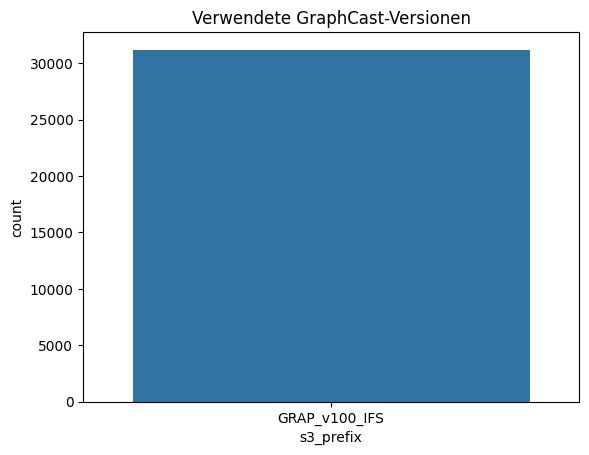

In [4]:
df["s3_prefix"].value_counts()

sns.countplot(
    data=df,
    x="s3_prefix"
)

plt.title("Verwendete GraphCast-Versionen")
plt.show()

Alle Läufe stammen aus `GRAP_v100_IFS`. Das Download-Skript sucht zuerst nach der neueren Version `v200`, hat für
unseren Zeitraum aber nichts gefunden. Für GraphCast gibt es also nur eine Modellversion.

In [5]:
forecast_sizes = (
    df.groupby("init_time")
      .size()
)

forecast_sizes.describe()

count    761.0
mean      41.0
std        0.0
min       41.0
25%       41.0
50%       41.0
75%       41.0
max       41.0
dtype: float64

In [6]:

expected_steps = 41

print(forecast_sizes[
    forecast_sizes != expected_steps
])

Series([], dtype: int64)


Wenn ein Lauf vorhanden ist, hat er alle 41 Schritte (0–240 h). Es gibt also keine unvollständigen Läufe, nur ganz fehlende.

## Fehlende Tage

Wir berechnen die fehlenden Starttage direkt aus den Daten: Welche Tage zwischen erstem und letztem Lauf haben keinen Lauf?

In [7]:
all_days = pd.date_range(
    start=df["init_time"].min(),
    end=df["init_time"].max(),
    freq="D"
)

present_days = pd.DatetimeIndex(df["init_time"].unique())
missing_days = all_days.difference(present_days)

print(f"{len(missing_days)} von {len(all_days)} Tagen fehlen ({len(missing_days) / len(all_days):.0%})")

201 von 962 Tagen fehlen (21%)


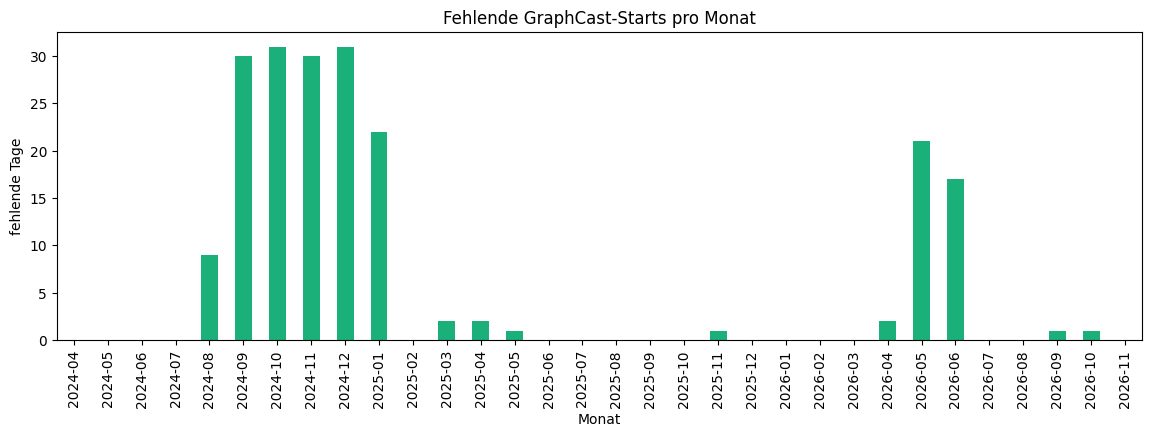

In [8]:
# Fehlende Tage pro Monat zählen
missing_per_month = (
    pd.Series(missing_days)
      .dt.to_period("M")
      .value_counts()
)

# Monate ohne Lücke mit 0 auffüllen
all_months = pd.period_range(all_days.min(), all_days.max(), freq="M")
missing_per_month = missing_per_month.reindex(all_months, fill_value=0)

plt.figure(figsize=(14,4))
missing_per_month.plot(kind="bar", color="#1baf7a")
plt.title("Fehlende GraphCast-Starts pro Monat")
plt.xlabel("Monat")
plt.ylabel("fehlende Tage")
plt.show()

**Wichtig:** Die Lücken sind nicht zufällig verteilt. Von Ende August 2024 bis Januar 2025 fehlt fast alles (ein ganzer
Winter), dazu große Teile von Mai und Juni 2026. Folgen:

- Für den Winter 2024/25 gibt es keine GraphCast-Daten. Ein Vergleich nach Jahreszeiten wäre verzerrt, wenn wir
  einfach alle vorhandenen Tage nehmen.
- Für einen fairen Vergleich aller Modelle nutzen wir in Notebook 06 nur die Tage, an denen **alle vier** Modelle
  einen Lauf haben.

## Leere Felder

Keine leeren Felder (NaN). Aber Achtung, siehe unten: Fehlwerte sind in dieser Datei als riesige Zahl gespeichert.

In [9]:
missing = pd.DataFrame({
    "count": df.isna().sum(),
    "percent":
        100 * df.isna().sum() / len(df)
})

display(missing)

,count,percent
init_time,0,0.0
s3_prefix,0,0.0
time,0,0.0
t2,0,0.0
apcp,0,0.0
longitude,0,0.0
latitude,0,0.0
temperature_2m,0,0.0
lead_time_h,0,0.0


## Temperaturverteilung

In [10]:
df["temperature_2m"].describe()

count    3.120100e+04
mean     4.856639e+34
std      6.941364e+35
min     -1.149010e+01
25%      6.194970e+00
50%      1.200045e+01
75%      1.658720e+01
max      9.969210e+36
Name: temperature_2m, dtype: float64

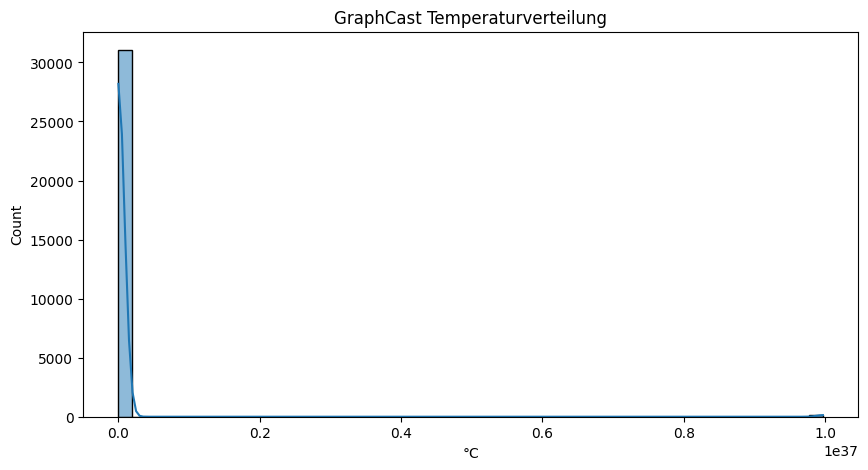

In [11]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["temperature_2m"],
    bins=50,
    kde=True
)

plt.xlabel("°C")
plt.title("GraphCast Temperaturverteilung")
plt.show()

Mittelwert und Maximum (≈ 10³⁶ °C) sind offensichtlich falsch, und das Histogramm ist dadurch unbrauchbar.
Die Ursache zeigen die nächsten Zellen.

In [12]:
# Sehr große Werte suchen
outliers = df[df["t2"] > 1000]

print(f"Anzahl verdächtiger Datensätze: {len(outliers)}")

outliers.head()

Anzahl verdächtiger Datensätze: 152


,init_time,s3_prefix,time,t2,apcp,longitude,latitude,temperature_2m,lead_time_h
24887,2026-06-18,GRAP_v100_IFS,2026-06-18,9.969210e+36,9.969210e+36,10.0,53.75,9.969210e+36,0.0
24928,2026-06-19,GRAP_v100_IFS,2026-06-19,9.969210e+36,9.969210e+36,10.0,53.75,9.969210e+36,0.0
24969,2026-06-20,GRAP_v100_IFS,2026-06-20,9.969210e+36,9.969210e+36,10.0,53.75,9.969210e+36,0.0
25010,2026-06-21,GRAP_v100_IFS,2026-06-21,9.969210e+36,9.969210e+36,10.0,53.75,9.969210e+36,0.0
25051,2026-06-22,GRAP_v100_IFS,2026-06-22,9.969210e+36,9.969210e+36,10.0,53.75,9.969210e+36,0.0


In [13]:
# Sehr kleine Werte suchen (unter 150 K)
outliers = df[df["t2"] < 150]

print(f"Anzahl verdächtiger Datensätze: {len(outliers)}")

outliers.head()

Anzahl verdächtiger Datensätze: 0


,init_time,s3_prefix,time,t2,apcp,longitude,latitude,temperature_2m,lead_time_h


In [14]:
# Sehr große Werte suchen
outliers = df[df["apcp"] > 1000]

print(f"Anzahl verdächtiger Datensätze: {len(outliers)}")

outliers.head()

Anzahl verdächtiger Datensätze: 304


,init_time,s3_prefix,time,t2,apcp,longitude,latitude,temperature_2m,lead_time_h
24887,2026-06-18,GRAP_v100_IFS,2026-06-18 00:00:00,9.969210e+36,9.969210e+36,10.0,53.75,9.969210e+36,0.0
24888,2026-06-18,GRAP_v100_IFS,2026-06-18 06:00:00,2.912903e+02,9.969210e+36,10.0,53.75,1.814030e+01,6.0
24928,2026-06-19,GRAP_v100_IFS,2026-06-19 00:00:00,9.969210e+36,9.969210e+36,10.0,53.75,9.969210e+36,0.0
24929,2026-06-19,GRAP_v100_IFS,2026-06-19 06:00:00,2.933772e+02,9.969210e+36,10.0,53.75,2.022717e+01,6.0
24969,2026-06-20,GRAP_v100_IFS,2026-06-20 00:00:00,9.969210e+36,9.969210e+36,10.0,53.75,9.969210e+36,0.0


### Fehlwerte bereinigen

Der Wert 9,97·10³⁶ ist der Standard-Platzhalter für „kein Wert“ in NetCDF-Dateien (`_FillValue`). Er steht seit dem
18.06.2026 in den Daten, und zwar nur bei Lead Time 0 (Temperatur und Niederschlag) und +6 h (nur Niederschlag).
Wir ersetzen ihn durch NaN. Lead Time 0 nutzen wir ohnehin nicht; betroffen ist also nur der Niederschlag bei +6 h in
den letzten Monaten.

In [15]:
fill_rows = df[(df["t2"] > 1000) | (df["apcp"] > 1000)]

print("Erster betroffener Lauf:", fill_rows["init_time"].min())

# Betroffene Zeilen pro Lead Time
fill_rows.groupby("lead_time_h").size()

Erster betroffener Lauf: 2026-06-18 00:00:00


lead_time_h
0.0    152
6.0    152
dtype: int64

In [16]:
# Platzhalter durch NaN ersetzen
df.loc[df["t2"] > 1000, "t2"] = np.nan
df.loc[df["apcp"] > 1000, "apcp"] = np.nan

# Celsius neu berechnen
df["temperature_2m"] = df["t2"] - 273.15

df["temperature_2m"].describe()

count    31049.000000
mean        11.395712
std          7.307086
min        -11.490100
25%          6.173200
50%         11.949700
75%         16.502770
max         36.726300
Name: temperature_2m, dtype: float64

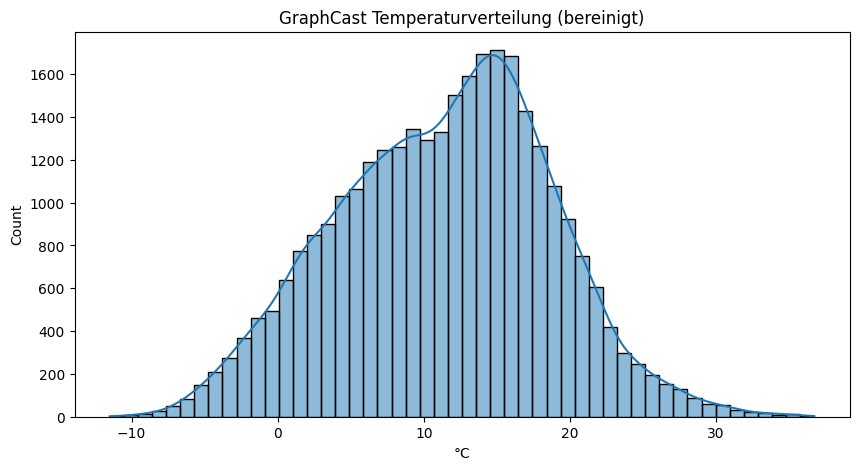

In [17]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["temperature_2m"],
    bins=50,
    kde=True
)

plt.xlabel("°C")
plt.title("GraphCast Temperaturverteilung (bereinigt)")
plt.show()

Nach der Bereinigung liegen die Temperaturen zwischen −11,5 °C und 36,7 °C, plausibel und ähnlich wie bei der DWD.

## Temperatur nach Lead Time

Dieselben Plots wie in Notebook 02. Das Zacken kommt von der Tageszeit (Start immer 00 UTC); die Streuung zeigt, wie
stark die Vorhersagen schwanken (Erklärung in Notebook 02).

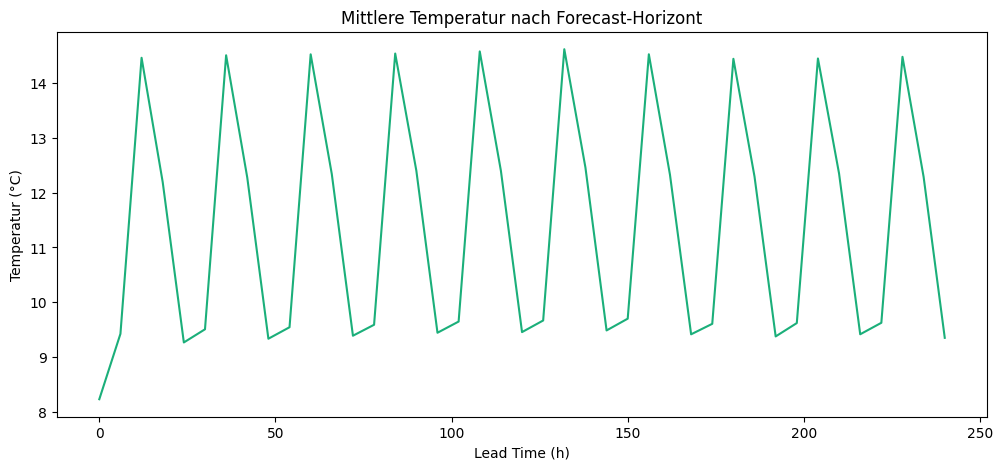

In [18]:
mean_by_lead = (
    df.groupby("lead_time_h")
      ["temperature_2m"]
      .mean()
)

plt.figure(figsize=(12,5))
mean_by_lead.plot(color="#1baf7a")
plt.title("Mittlere Temperatur nach Forecast-Horizont")
plt.xlabel("Lead Time (h)")
plt.ylabel("Temperatur (°C)")
plt.show()

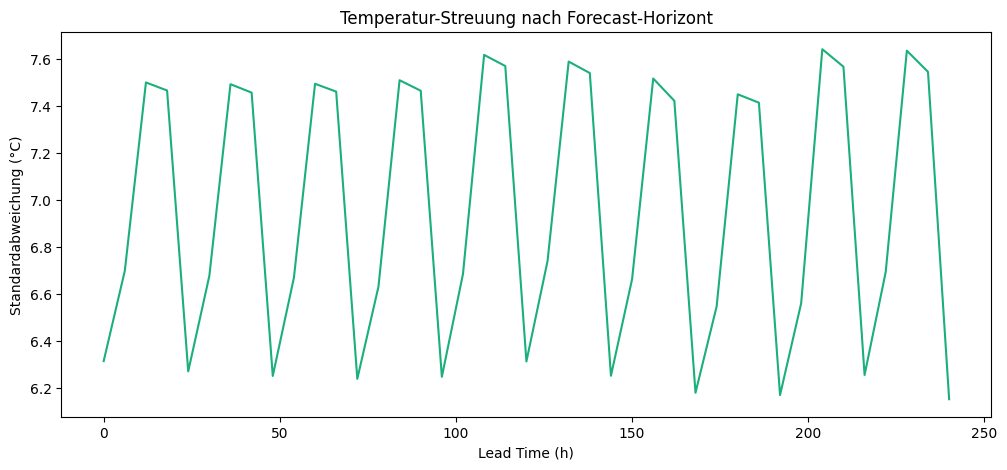

In [19]:
std_by_lead = (
    df.groupby("lead_time_h")
      ["temperature_2m"]
      .std()
)

plt.figure(figsize=(12,5))
std_by_lead.plot(color="#1baf7a")
plt.title("Temperatur-Streuung nach Forecast-Horizont")
plt.xlabel("Lead Time (h)")
plt.ylabel("Standardabweichung (°C)")
plt.show()

## Niederschlag

`apcp` ist die Summe über die 6 Stunden **vor** `time`, in Metern. Mal 1000 ergibt mm pro 6 h.

In [20]:
precip = df[df["lead_time_h"] > 0].copy()

# Meter in Millimeter umrechnen
precip["precip_mm_6h"] = precip["apcp"] * 1000

negative = precip[precip["precip_mm_6h"] < 0]

print(f"Negative Werte: {len(negative)}")
print(f"Kleinster Wert: {negative['precip_mm_6h'].min():.3f} mm")

Negative Werte: 3490
Kleinster Wert: -0.067 mm


Es gibt einige tausend winzige negative Werte (höchstens −0,07 mm). Negativer Niederschlag ist physikalisch unmöglich;
das sind Rundungsreste des Modells. Wir setzen sie auf 0.

In [21]:
# Negative Rundungsreste auf 0 setzen
precip["precip_mm_6h"] = precip["precip_mm_6h"].clip(lower=0)

exactly_zero = (precip["precip_mm_6h"] == 0).mean()
almost_dry = (precip["precip_mm_6h"] < 0.1).mean()

print(f"Genau 0 mm: {exactly_zero:.1%}")
print(f"Unter 0,1 mm (praktisch trocken): {almost_dry:.1%}")

precip["precip_mm_6h"].describe()

Genau 0 mm: 11.5%
Unter 0,1 mm (praktisch trocken): 52.1%


count    30288.000000
mean         0.494572
std          1.039720
min          0.000000
25%          0.016937
50%          0.085386
75%          0.438093
max         18.726263
Name: precip_mm_6h, dtype: float64

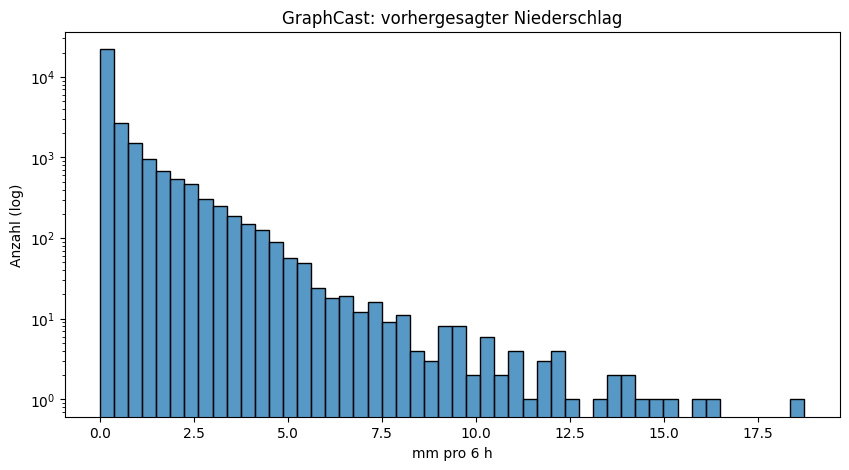

In [22]:
plt.figure(figsize=(10,5))

sns.histplot(
    precip["precip_mm_6h"],
    bins=50
)

plt.yscale("log")
plt.title("GraphCast: vorhergesagter Niederschlag")
plt.xlabel("mm pro 6 h")
plt.ylabel("Anzahl (log)")
plt.show()

GraphCast sagt nur in etwa 12 % der 6-h-Fenster exakt 0 mm voraus, in 52 % weniger als 0,1 mm (DWD: rund 75 %
trocken). Wie AIFS lässt GraphCast also sehr oft ein bisschen regnen.

## Erkenntnisse

- 761 Läufe mit je 41 Schritten (0–240 h), alle aus `GRAP_v100_IFS`.
- **201 von 962 Tagen fehlen (21 %)**, vor allem Ende August 2024 bis Januar 2025 und Mai/Juni 2026. Für faire
  Vergleiche nur die gemeinsamen Tage aller Modelle verwenden.
- **Fehlwerte als Zahl kodiert** (9,97·10³⁶, seit 18.06.2026, nur Lead Time 0 und +6 h) → durch NaN ersetzt.
- **Andere Einheiten** als bei den anderen Modellen: Kelvin → °C, Meter → mm. Winzige negative Niederschläge → 0.
- Nach der Bereinigung plausible Werte. Niederschlag: wie AIFS selten ganz trocken → passt zur Glättungs-Hypothese.